# SARIMA EDA — Stationarity & ACF/PACF Analysis

**Mục tiêu:** Phân tích stationarity để quyết định tham số `d`, `D` và range `p/q`, `P/Q`  
cho từng chuỗi (Total, Online, Store, Mobile) trước khi chạy `train_sarima.py`.

**Input:** `data/processed/weekly_total.csv`, `data/processed/weekly_channel.csv`  
**Output:** `reports/sarima/eda_stationarity.csv`, `reports/sarima/eda_acf_pacf_{series}.png`

**EDA notebook trước đã có:** trend, STL decomposition, outliers, channel comparison.  
**Notebook này BỔ SUNG:** ADF/KPSS tests, ACF/PACF chi tiết, quyết định tham số.

---
**Kết luận từ EDA trước (tóm tắt):**
- Seasonality **yếu** (biên độ STL seasonal < biên độ residual)
- Không có trend tăng/giảm rõ rệt dài hạn
- CV ~0.36–0.37 mỗi kênh, CV tổng = 0.22
- Khuyến nghị: ưu tiên D=0, D=1 chỉ khi seasonal ACF tại lag 52 còn spike rõ

## 0. Imports & Config

In [7]:
import warnings
warnings.filterwarnings('ignore')

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ── Paths ──────────────────────────────────────────────────────────────────
_NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = _NOTEBOOK_DIR.parent if _NOTEBOOK_DIR.name == 'notebooks' else _NOTEBOOK_DIR
os.chdir(PROJECT_ROOT)  # Đảm bảo working directory luôn đồng nhất tại project root

DATA_DIR   = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports' / 'sarima'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

assert (DATA_DIR / 'weekly_total.csv').exists(), f"Không tìm thấy data tại: {DATA_DIR}"
print("Project root :", PROJECT_ROOT)
print("DATA_DIR OK  :", DATA_DIR)
print("REPORT_DIR OK:", REPORT_DIR)

# ── Plot style ─────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.grid': True,
    'grid.alpha': 0.3,
})
PALETTE = {'Total': '#4C72B0', 'Online': '#DD8452', 'Store': '#55A868', 'Mobile': '#C44E52'}

print('Imports OK')


Project root : D:\DataMining\Project\retail-revenue-forecasting
DATA_DIR OK  : D:\DataMining\Project\retail-revenue-forecasting\data\processed
REPORT_DIR OK: D:\DataMining\Project\retail-revenue-forecasting\reports\sarima
Imports OK


## 1. Load dữ liệu

In [8]:
# ── Load weekly_total ───────────────────────────────────────────────
weekly_total = pd.read_csv(
    DATA_DIR / 'weekly_total.csv',
    parse_dates=['week_start'],
)
weekly_total = weekly_total.set_index('week_start').sort_index()

# LỌC LẤY TẬP TRAIN 1 (2019-2022) ĐỂ PHÂN TÍCH TRÁNH DATA LEAKAGE
weekly_total = weekly_total[weekly_total['split_year'] <= 2022]

# ── Load weekly_channel ─────────────────────────────────────────────
weekly_channel = pd.read_csv(
    DATA_DIR / 'weekly_channel.csv',
    parse_dates=['week_start'],
)
weekly_channel = weekly_channel.set_index('week_start').sort_index()

# LỌC LẤY TẬP TRAIN 1 (2019-2022)
weekly_channel = weekly_channel[weekly_channel['split_year'] <= 2022]

# Tách riêng từng channel
series_dict = {
    'Total': weekly_total['revenue'],
    'Online': weekly_channel[weekly_channel['channel'] == 'Online']['revenue'],
    'Store': weekly_channel[weekly_channel['channel'] == 'Store']['revenue'],
    'Mobile': weekly_channel[weekly_channel['channel'] == 'Mobile']['revenue'],
}

print('Dữ liệu TRAIN (2019-2022) dùng cho EDA đã load thành công:')
for name, s in series_dict.items():
  print(
      f'  {name:7s}: {len(s)} tuần ({s.index.min().date()} ->'
      f' {s.index.max().date()})'
)

Dữ liệu TRAIN (2019-2022) dùng cho EDA đã load thành công:
  Total  : 209 tuần (2018-12-31 -> 2022-12-26)
  Online : 209 tuần (2018-12-31 -> 2022-12-26)
  Store  : 209 tuần (2018-12-31 -> 2022-12-26)
  Mobile : 209 tuần (2018-12-31 -> 2022-12-26)


### Quy tắc diễn giải ADF + KPSS

| ADF p-value | KPSS p-value | Diễn giải | Hành động với `d` |
|---|---|---|---|
| `< 0.05` | `> 0.05` | Hai test cùng ủng hộ stationarity | **Chọn `d = 0`** |
| `> 0.05` | `< 0.05` | Hai test cùng chỉ ra non-stationarity | **Thử `d = 1`, sau đó kiểm tra lại** |
| `> 0.05` | `> 0.05` | Kết quả chưa đủ rõ ràng | **Không kết luận; xem thêm diagnostics và thử `d = 1` nếu cần** |
| `< 0.05` | `< 0.05` | Có thể có trend-stationarity hoặc khác biệt về giả định kiểm định | **Không tự động chọn `d = 1`; xem trend/detrending và diagnostics** |

> **Lưu ý:** ADF và KPSS không phải là quy tắc tự động quyết định `d`. Kết quả kiểm định được sử dụng cùng với đồ thị chuỗi thời gian, ACF/PACF và kiểm tra lại stationarity sau khi differencing để lựa chọn `d` phù hợp.
>
> **Lưu ý về KPSS:** `statsmodels` có thể báo `p-value = 0.01` hoặc `0.10` khi thống kê kiểm định nằm ngoài phạm vi của bảng critical values. Vì vậy, các giá trị này nên được hiểu là **boundary**, không nhất thiết là p-value chính xác.

In [9]:
def run_stationarity_tests(series: pd.Series, series_name: str) -> dict:
    """Chạy ADF và KPSS trên chuỗi gốc và chuỗi sai phân bậc 1."""
    results = {'series': series_name}

    # ── ADF ─────────────────────────────────────────────────────────────────
    adf_orig = adfuller(series.dropna(), autolag='AIC')
    results['adf_stat_orig'] = round(adf_orig[0], 4)
    results['adf_p_orig']    = round(adf_orig[1], 4)

    # ── KPSS ────────────────────────────────────────────────────────────────
    kpss_orig = kpss(series.dropna(), regression='c', nlags='auto')
    results['kpss_stat_orig'] = round(kpss_orig[0], 4)
    results['kpss_p_orig']    = round(kpss_orig[1], 4)

    # ── Sau sai phân bậc 1 ──────────────────────────────────────────────────
    diff1 = series.diff().dropna()
    adf_d1  = adfuller(diff1, autolag='AIC')
    kpss_d1 = kpss(diff1, regression='c', nlags='auto')
    results['adf_p_diff1']  = round(adf_d1[1], 4)
    results['kpss_p_diff1'] = round(kpss_d1[1], 4)

    # ── Kết luận d ──────────────────────────────────────────────────────────
    if results['adf_p_orig'] < 0.05 and results['kpss_p_orig'] > 0.05:
        results['conclusion_d'] = 'd=0  (stationary)'
    elif results['adf_p_orig'] > 0.05 or results['kpss_p_orig'] < 0.05:
        results['conclusion_d'] = 'd=1  (non-stationary → difference)'
    else:
        results['conclusion_d'] = 'd=?  (ambiguous, check ACF/PACF)'

    return results


# ── Chạy cho 4 series ───────────────────────────────────────────────────────
stat_rows = []
for name, s in series_dict.items():
    row = run_stationarity_tests(s, name)
    stat_rows.append(row)

stat_df = pd.DataFrame(stat_rows).set_index('series')

# ── Hiển thị ────────────────────────────────────────────────────────────────
print('=' * 80)
print('STATIONARITY TEST RESULTS')
print('=' * 80)
for name, row in stat_df.iterrows():
    print(f'\n[{name}]')
    print(f'  Original:   ADF p={row.adf_p_orig:.4f}  KPSS p={row.kpss_p_orig:.4f}')
    print(f'  After d=1:  ADF p={row.adf_p_diff1:.4f}  KPSS p={row.kpss_p_diff1:.4f}')
    print(f'  → {row.conclusion_d}')

# ── Lưu CSV ─────────────────────────────────────────────────────────────────
stat_df.to_csv(REPORT_DIR / 'eda_stationarity.csv')
print(f'\nSaved: {REPORT_DIR}/eda_stationarity.csv')

STATIONARITY TEST RESULTS

[Total]
  Original:   ADF p=0.0000  KPSS p=0.1000
  After d=1:  ADF p=0.0000  KPSS p=0.1000
  → d=0  (stationary)

[Online]
  Original:   ADF p=0.0000  KPSS p=0.1000
  After d=1:  ADF p=0.0000  KPSS p=0.1000
  → d=0  (stationary)

[Store]
  Original:   ADF p=0.0000  KPSS p=0.1000
  After d=1:  ADF p=0.0000  KPSS p=0.1000
  → d=0  (stationary)

[Mobile]
  Original:   ADF p=0.0000  KPSS p=0.0888
  After d=1:  ADF p=0.0000  KPSS p=0.1000
  → d=0  (stationary)

Saved: D:\DataMining\Project\retail-revenue-forecasting\reports\sarima/eda_stationarity.csv


## 3. ACF / PACF Plots

**Cách đọc:**
- **ACF chuỗi gốc:** Nếu decay chậm → non-stationary, cần differencing
- **PACF chuỗi gốc:** Cutoff sau lag 1/2 → gợi ý AR(p)
- **ACF sau diff(1):** Cutoff âm mạnh ở lag 1 → gợi ý MA(1); nhiều spike âm → có thể over-differenced
- **PACF sau diff(1):** Cutoff sau lag 1/2 → gợi ý p=1/2
- **Spike tại lag 52/104:** Seasonal dependency → thử P=1 hoặc Q=1

Confidence band (đường ngang đứt): ±1.96/√n ≈ ±0.102 với n=366

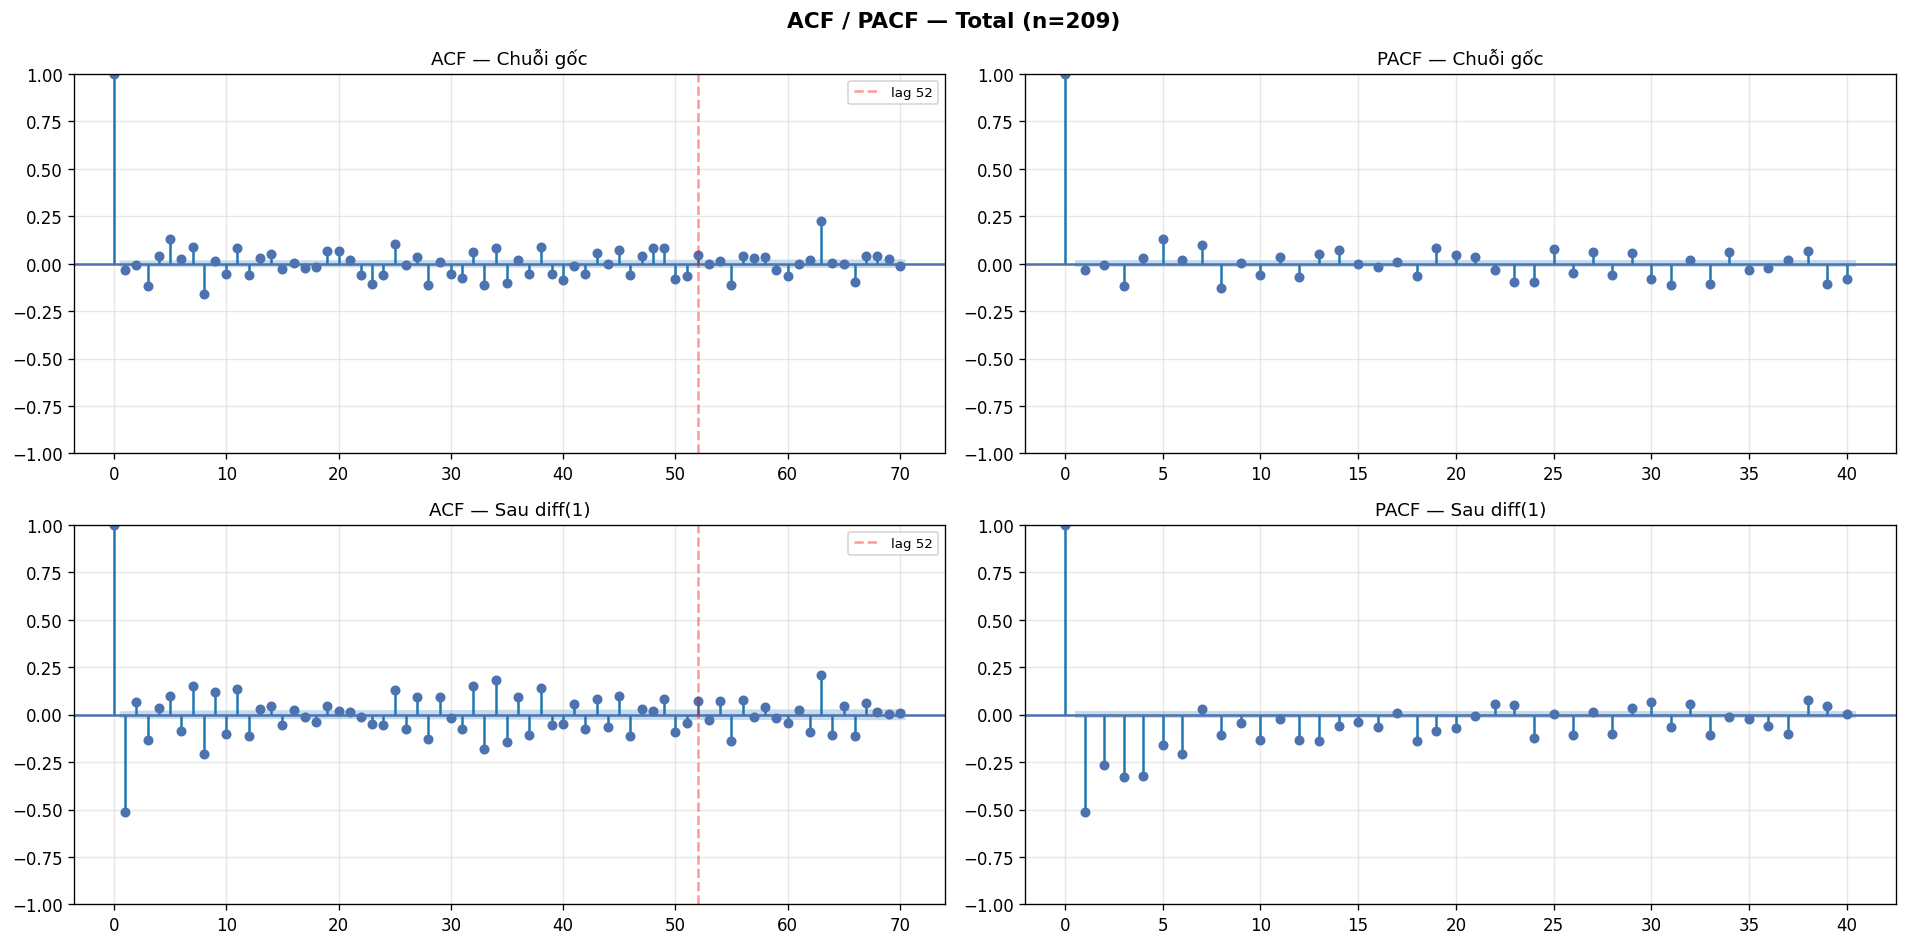

Saved: D:\DataMining\Project\retail-revenue-forecasting\reports\sarima\eda_acf_pacf_total.png


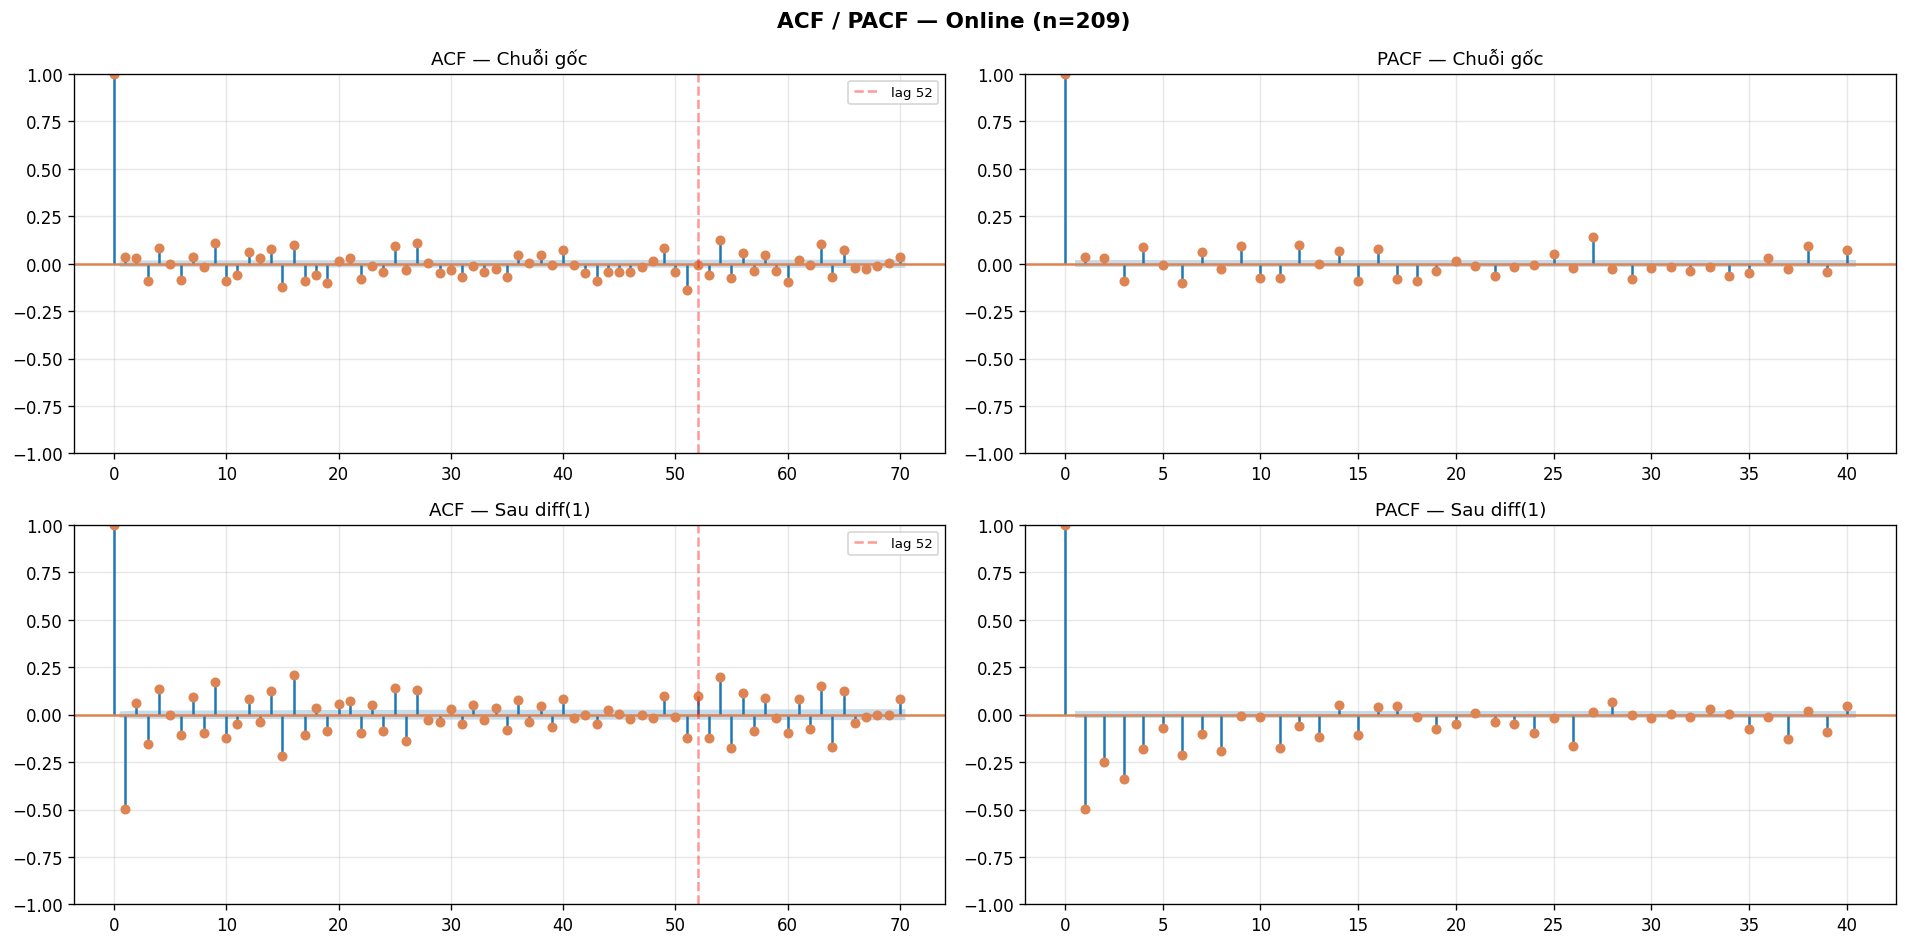

Saved: D:\DataMining\Project\retail-revenue-forecasting\reports\sarima\eda_acf_pacf_online.png


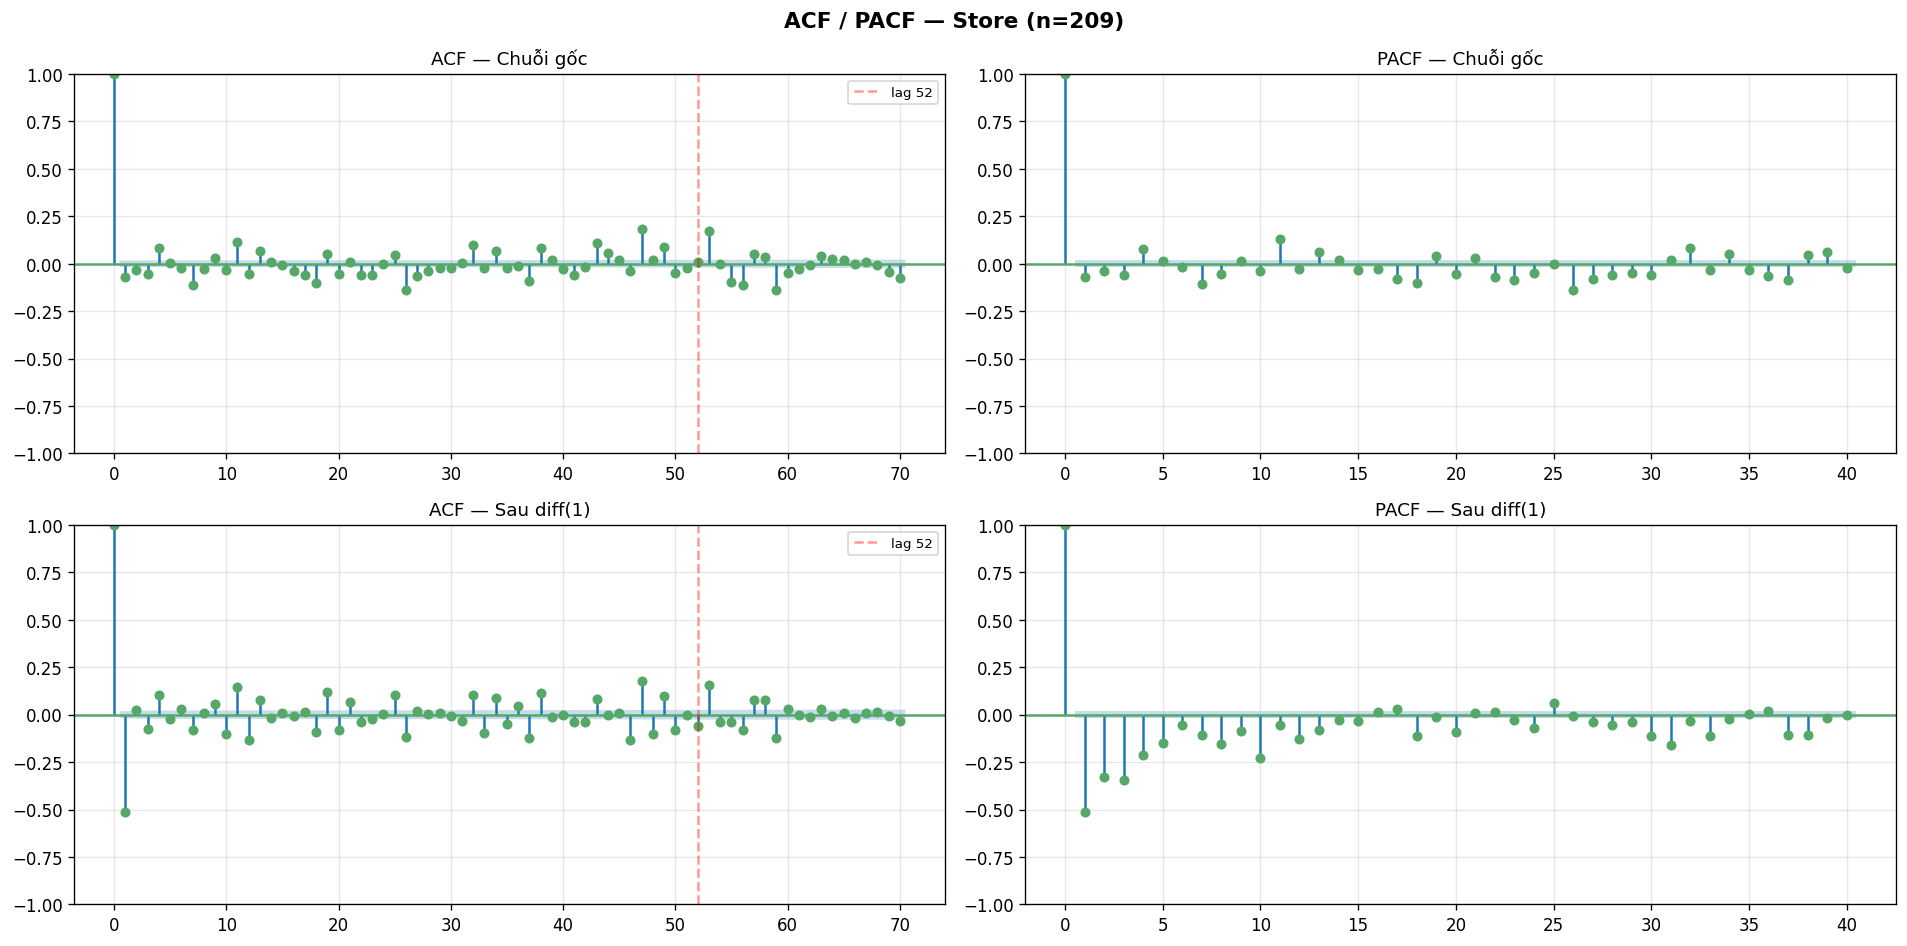

Saved: D:\DataMining\Project\retail-revenue-forecasting\reports\sarima\eda_acf_pacf_store.png


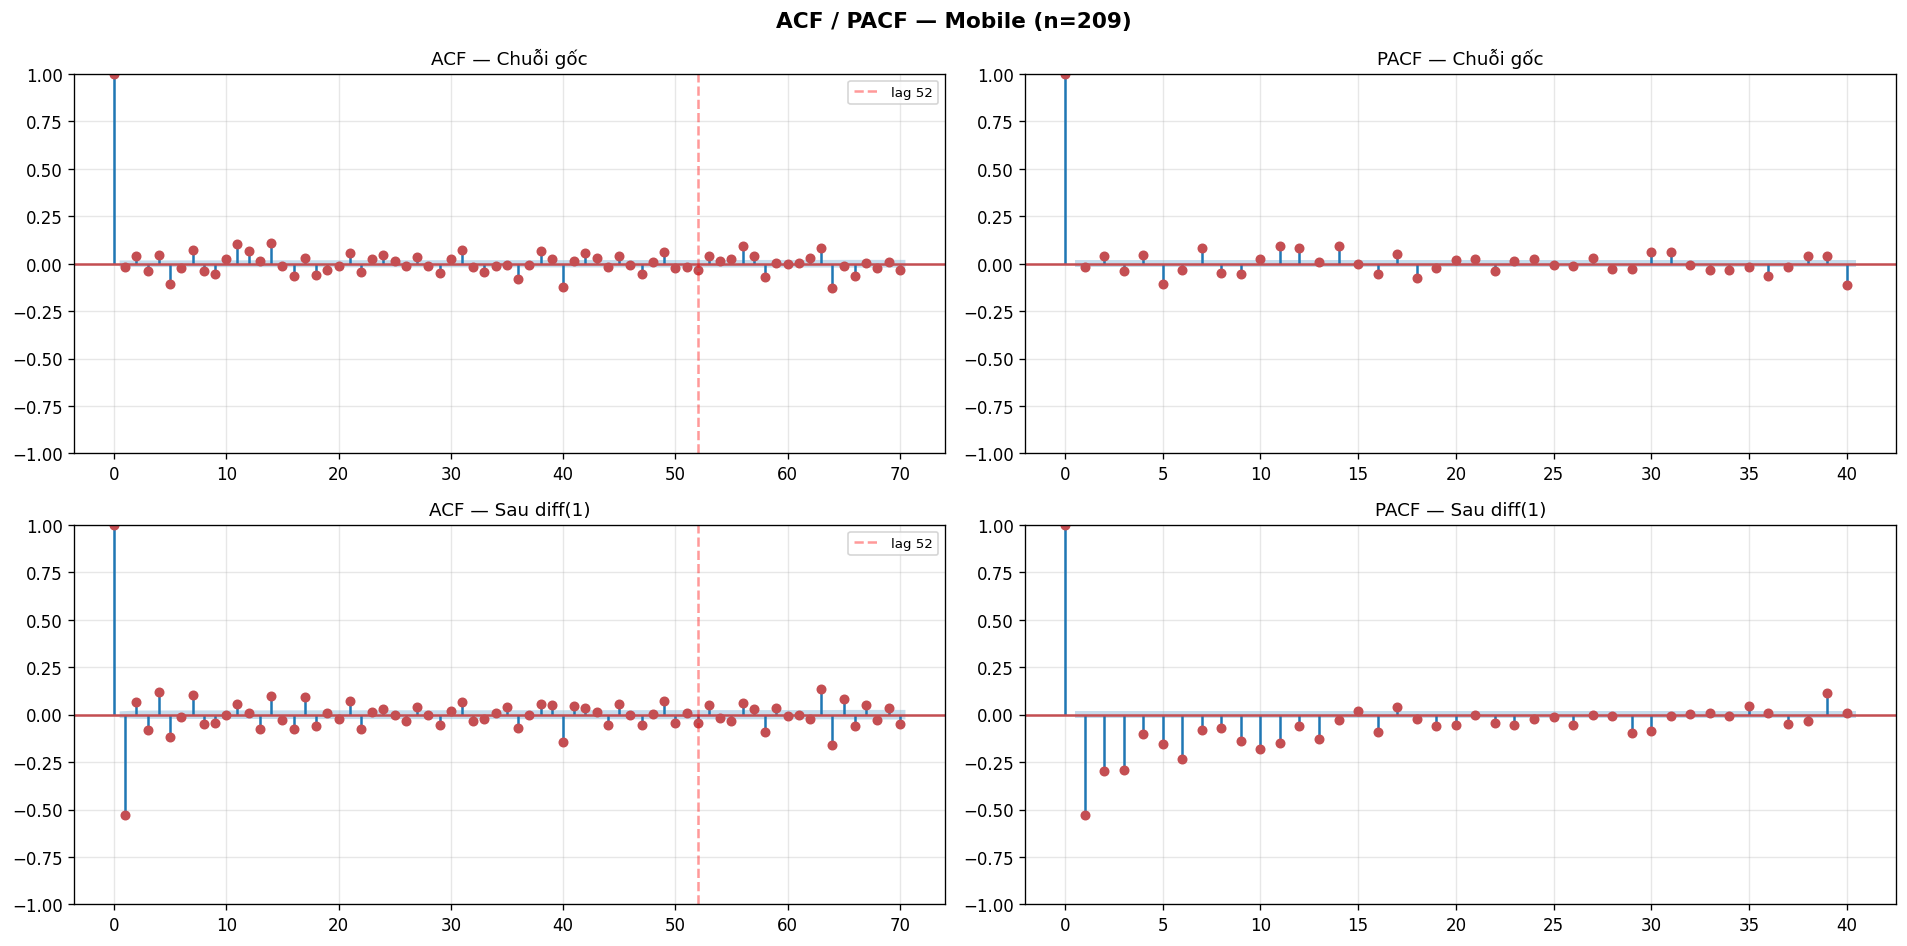

Saved: D:\DataMining\Project\retail-revenue-forecasting\reports\sarima\eda_acf_pacf_mobile.png


In [10]:
def plot_acf_pacf_full(series: pd.Series, series_name: str, color: str) -> None:
    """
    4-panel figure:
      Row 1: ACF gốc (lags 0-70) | PACF gốc (lags 1-40)
      Row 2: ACF diff(1) (lags 0-70) | PACF diff(1) (lags 1-40)
    """
    diff1 = series.diff().dropna()
    n_lags_long = 70   # đủ dài để thấy lag 52
    n_lags_pacf = 40

    fig, axes = plt.subplots(2, 2, figsize=(16, 8))
    fig.suptitle(f'ACF / PACF — {series_name} (n={len(series)})', fontsize=13, fontweight='bold')

    # Row 0 — chuỗi gốc
    plot_acf(series.dropna(), lags=n_lags_long, ax=axes[0, 0], color=color, alpha=0.8)
    axes[0, 0].set_title('ACF — Chuỗi gốc')
    axes[0, 0].axvline(52, color='red', linestyle='--', alpha=0.4, label='lag 52')
    axes[0, 0].legend(fontsize=8)

    plot_pacf(series.dropna(), lags=n_lags_pacf, ax=axes[0, 1], color=color, alpha=0.8, method='ywm')
    axes[0, 1].set_title('PACF — Chuỗi gốc')

    # Row 1 — sau diff(1)
    plot_acf(diff1, lags=n_lags_long, ax=axes[1, 0], color=color, alpha=0.8)
    axes[1, 0].set_title('ACF — Sau diff(1)')
    axes[1, 0].axvline(52, color='red', linestyle='--', alpha=0.4, label='lag 52')
    axes[1, 0].legend(fontsize=8)

    plot_pacf(diff1, lags=n_lags_pacf, ax=axes[1, 1], color=color, alpha=0.8, method='ywm')
    axes[1, 1].set_title('PACF — Sau diff(1)')

    plt.tight_layout()
    out_path = REPORT_DIR / f'eda_acf_pacf_{series_name.lower()}.png'
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {out_path}')


# ── Vẽ cho 4 series ─────────────────────────────────────────────────────────
for name, s in series_dict.items():
    plot_acf_pacf_full(s, name, PALETTE[name])

## 4. Seasonal ACF — Tập trung vào lag 52 và 104

Kiểm tra xem seasonal dependency có đủ mạnh để dùng D=1 hay P/Q seasonal terms không.

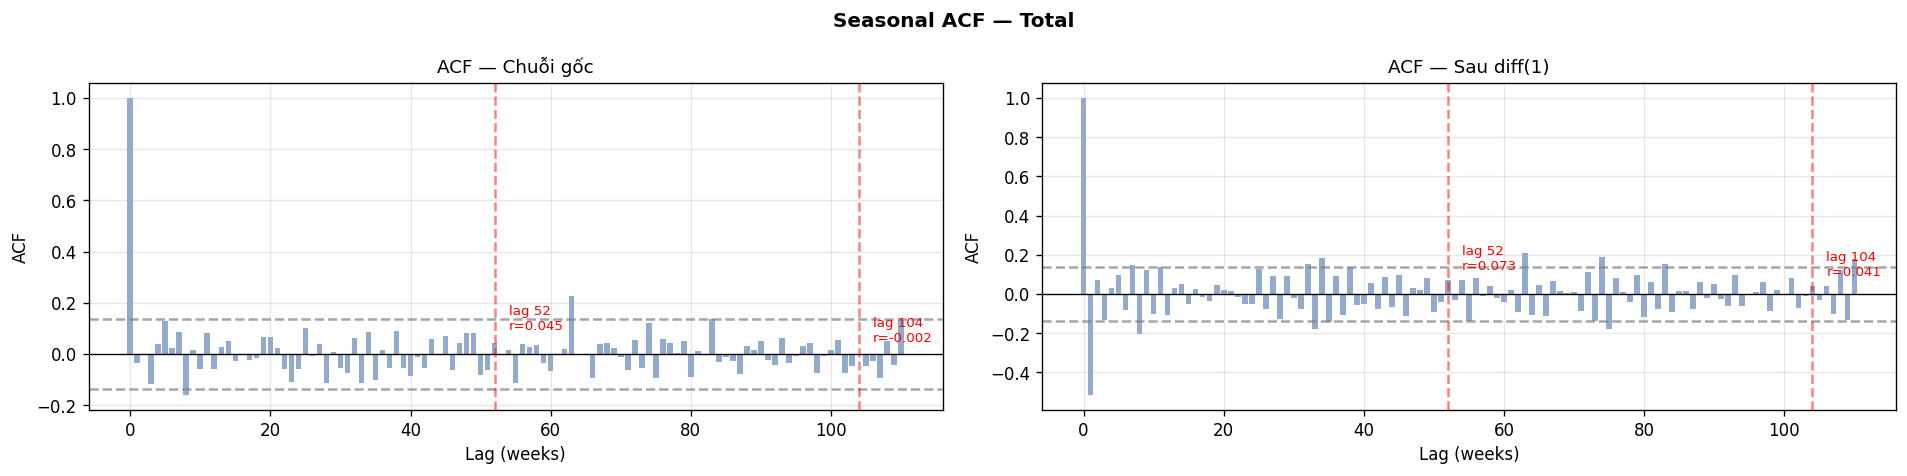

[Total] Seasonal ACF (±0.136 confidence band):
  lag 52 gốc   = 0.045     → trong band
  lag 104 gốc  = -0.002
  lag 52 diff1 = 0.073    → spike giảm



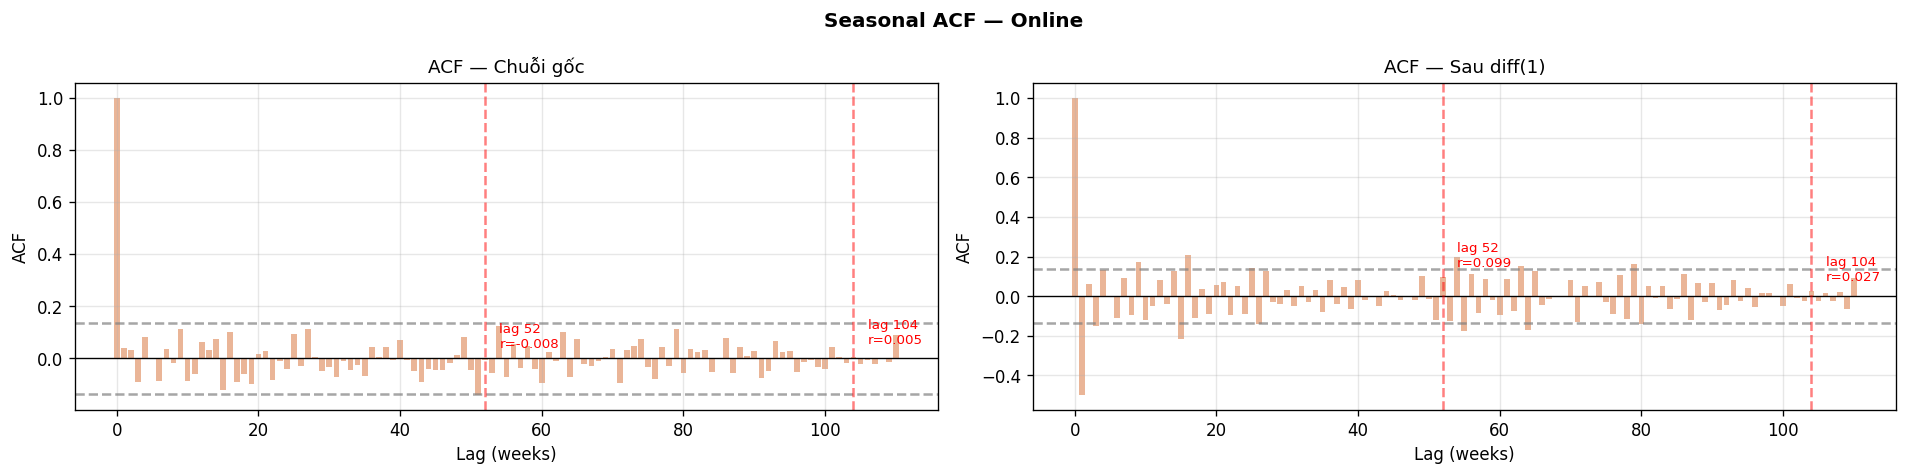

[Online] Seasonal ACF (±0.136 confidence band):
  lag 52 gốc   = -0.008     → trong band
  lag 104 gốc  = 0.005
  lag 52 diff1 = 0.099    → spike giảm



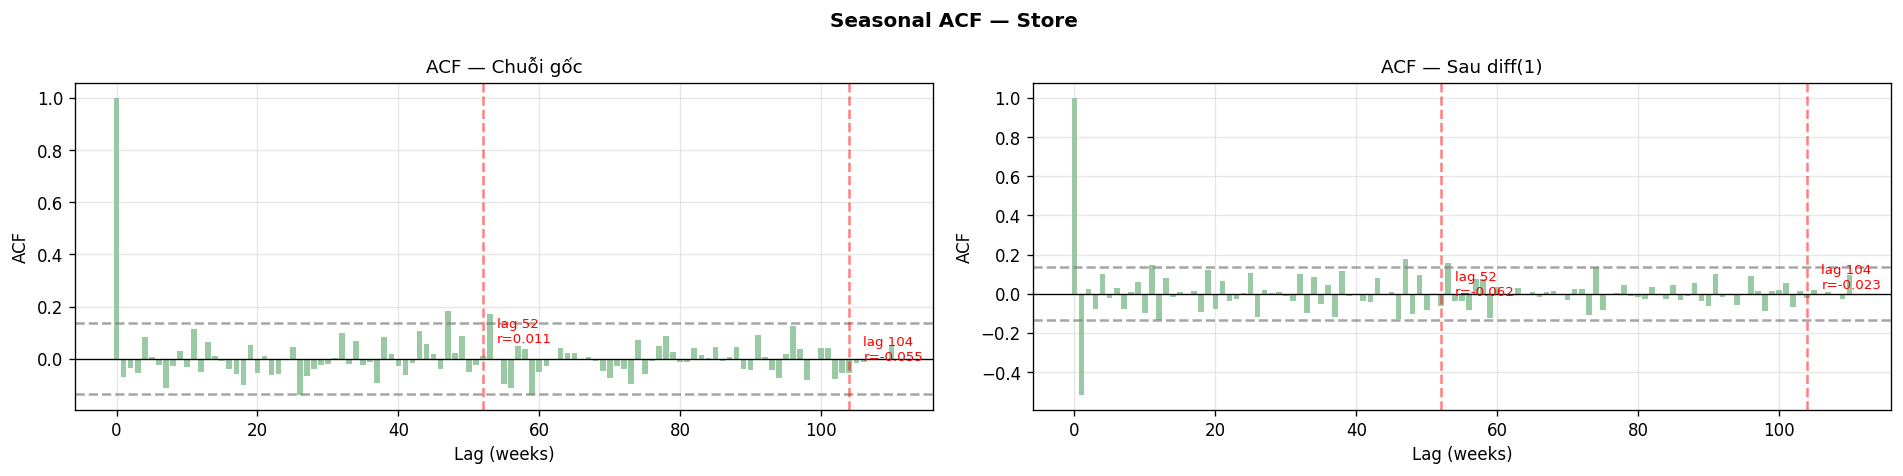

[Store] Seasonal ACF (±0.136 confidence band):
  lag 52 gốc   = 0.011     → trong band
  lag 104 gốc  = -0.055
  lag 52 diff1 = -0.062    → spike giảm



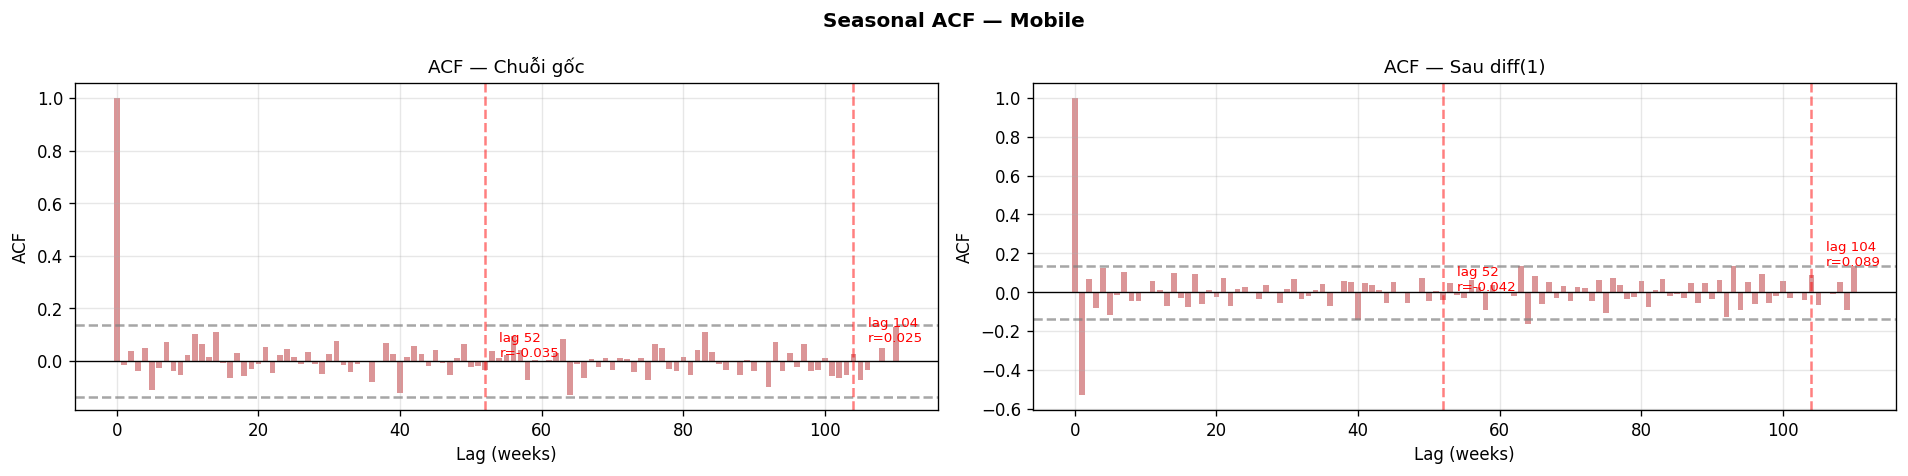

[Mobile] Seasonal ACF (±0.136 confidence band):
  lag 52 gốc   = -0.035     → trong band
  lag 104 gốc  = 0.025
  lag 52 diff1 = -0.042    → spike giảm

        acf_lag52_orig  acf_lag104_orig  acf_lag52_diff1  conf_band
series                                                             
Total            0.045           -0.002            0.073      0.136
Online          -0.008            0.005            0.099      0.136
Store            0.011           -0.055           -0.062      0.136
Mobile          -0.035            0.025           -0.042      0.136


In [11]:
def plot_seasonal_acf(series: pd.Series, series_name: str, color: str) -> dict:
    """
    Vẽ ACF với lags 0-110, nhấn mạnh lag 52 và 104.
    Trả về dict: {acf_lag52_orig, acf_lag104_orig, acf_lag52_diff1}
    """
    diff1 = series.diff().dropna()
    n = len(series.dropna())
    conf_band = 1.96 / np.sqrt(n)

    acf_orig  = acf(series.dropna(),  nlags=110, fft=True)
    acf_diff1 = acf(diff1,            nlags=110, fft=True)

    fig, axes = plt.subplots(1, 2, figsize=(16, 4))
    fig.suptitle(f'Seasonal ACF — {series_name}', fontsize=12, fontweight='bold')

    for ax, acf_vals, title_suffix in [
        (axes[0], acf_orig,  'Chuỗi gốc'),
        (axes[1], acf_diff1, 'Sau diff(1)'),
    ]:
        lags = range(len(acf_vals))
        ax.bar(lags, acf_vals, color=color, alpha=0.6, width=0.8)
        ax.axhline( conf_band, linestyle='--', color='gray', alpha=0.7)
        ax.axhline(-conf_band, linestyle='--', color='gray', alpha=0.7)
        ax.axhline(0, color='black', linewidth=0.8)
        # Đánh dấu lag 52 và 104
        for lag_mark in [52, 104]:
            if lag_mark < len(acf_vals):
                ax.axvline(lag_mark, color='red', linestyle='--', alpha=0.5)
                ax.annotate(f'lag {lag_mark}\nr={acf_vals[lag_mark]:.3f}',
                            xy=(lag_mark, acf_vals[lag_mark]),
                            xytext=(lag_mark + 2, acf_vals[lag_mark] + 0.05),
                            fontsize=8, color='red')
        ax.set_title(f'ACF — {title_suffix}')
        ax.set_xlabel('Lag (weeks)')
        ax.set_ylabel('ACF')

    plt.tight_layout()
    plt.show()

    result = {
        'series': series_name,
        'acf_lag52_orig':  round(acf_orig[52],  3) if 52  < len(acf_orig)  else None,
        'acf_lag104_orig': round(acf_orig[104], 3) if 104 < len(acf_orig)  else None,
        'acf_lag52_diff1': round(acf_diff1[52], 3) if 52  < len(acf_diff1) else None,
        'conf_band':       round(conf_band, 3),
    }

    # In nhận xét
    print(f'[{series_name}] Seasonal ACF (±{conf_band:.3f} confidence band):')
    print(f'  lag 52 gốc   = {result["acf_lag52_orig"]:.3f}   '
          f'  → {"SPIKE (|r|>band)" if abs(result["acf_lag52_orig"]) > conf_band else "trong band"}')
    print(f'  lag 104 gốc  = {result["acf_lag104_orig"]:.3f}')
    print(f'  lag 52 diff1 = {result["acf_lag52_diff1"]:.3f}  '
          f'  → {"còn spike sau diff" if abs(result["acf_lag52_diff1"]) > conf_band else "spike giảm"}')
    print()
    return result


# ── Chạy cho 4 series ───────────────────────────────────────────────────────
seasonal_rows = []
for name, s in series_dict.items():
    row = plot_seasonal_acf(s, name, PALETTE[name])
    seasonal_rows.append(row)

seasonal_df = pd.DataFrame(seasonal_rows).set_index('series')
print(seasonal_df)

## 5. Bảng kết luận — Candidate Space

Tổng hợp kết quả ADF/KPSS và ACF/PACF để quyết định không gian tham số cho `train_sarima.py`.

**Hướng dẫn điền:**
- `d`: từ ADF/KPSS (Section 2)
- `D`: D được xem xét dựa trên bằng chứng về seasonal non-stationarity.
Seasonal ACF tại lag 52/104 được sử dụng như diagnostic hỗ trợ.
Nếu không có seasonal spike rõ ràng và chuỗi gốc đã stationary,
ưu tiên D=0.
- `p_max`, `q_max`: nhìn PACF và ACF sau differencing, thường 0–2
- `P_max`, `Q_max`: nhìn seasonal PACF/ACF, thường 0–1

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  ĐIỀN VÀO ĐÂY sau khi xem kết quả Section 2, 3, 4                      ║
# ║  Mỗi giá trị phải có logic từ plots/tests ở trên                        ║
# ╚══════════════════════════════════════════════════════════════════════════╝

candidate_space = {
    # series_name: {d, D, p_max, q_max, P_max, Q_max, notes}
    'Total': {
        'd': 0,      # ← Điền sau khi xem Section 2 (ADF/KPSS)
        'D': 0,      # ← Điền sau khi xem Section 4 (seasonal ACF)
        'p_max': 2,     # Giới hạn từ dataset nhỏ (209 tuần train)
        'q_max': 2,
        'P_max': 1,
        'Q_max': 1,
        'notes': (
            'ADF/KPSS indicate stationarity on original series (d=0). '
            'Seasonal ACF at lag 52/104 is within confidence band, '
            'including after diff(1), so D=0. '
            'Original ACF/PACF show weak short-term dependence; '
            'keep p,q <= 2 due to only 209 training observations. '
            'Seasonal P/Q kept at 0-1 only for controlled exploratory testing.'
        ),    # nhận xét về ACF/PACF pattern
    },
    'Online': {
        'd': 0,
        'D': 0,
        'p_max': 2,
        'q_max': 2,
        'P_max': 1,
        'Q_max': 1,
        'notes': (
            'ADF/KPSS indicate stationarity on original series (d=0). '
            'Seasonal ACF at lag 52/104 remains within confidence band '
            'after diff(1), so D=0. '
            'Original ACF/PACF show no strong low-order cutoff pattern; '
            'keep p,q <= 2. Seasonal P/Q limited to 0-1 for controlled testing.'
        ),
    },
    'Store': {
        'd': 0,
        'D': 0,
        'p_max': 2,
        'q_max': 2,
        'P_max': 1,
        'Q_max': 1,
        'notes': (
            'ADF/KPSS indicate stationarity on original series (d=0). '
            'Seasonal ACF at lag 52/104 is within confidence band '
            'before and after diff(1), so D=0. '
            'Original ACF/PACF show weak short-term dependence; '
            'keep p,q <= 2 and limit seasonal terms to P/Q <= 1.'
        ),
    },
    'Mobile': {
        'd': 0,
        'D': 0,
        'p_max': 2,
        'q_max': 2,
        'P_max': 1,
        'Q_max': 1,
        'notes': (
            'ADF/KPSS indicate stationarity on original series (d=0). '
            'Seasonal ACF at lag 52/104 is within confidence band '
            'before and after diff(1), so D=0. '
            'Original ACF/PACF show weak short-term dependence; '
            'keep p,q <= 2 due to limited sample size. '
            'Seasonal P/Q limited to 0-1 for controlled exploratory testing.'
        ),
    },
}

# Hiển thị bảng kết luận
conclusion_df = pd.DataFrame(candidate_space).T
print('=' * 70)
print('CANDIDATE SPACE DECISIONS')
print('(Cập nhật d/D/notes sau khi xem plots bên trên)')
print('=' * 70)
print(conclusion_df.to_string())

# Lưu — dùng lại khi viết manual candidates trong train_sarima.py
conclusion_df.to_csv(REPORT_DIR / 'eda_candidate_space.csv')
print(f'\nSaved: {REPORT_DIR}/eda_candidate_space.csv')

CANDIDATE SPACE DECISIONS
(Cập nhật d/D/notes sau khi xem plots bên trên)
        d  D p_max q_max P_max Q_max                                                                                                                                                                                                                                                                                                                      notes
Total   0  0     2     2     1     1  ADF/KPSS indicate stationarity on original series (d=0). Seasonal ACF at lag 52/104 is within confidence band, including after diff(1), so D=0. Original ACF/PACF show weak short-term dependence; keep p,q <= 2 due to only 209 training observations. Seasonal P/Q kept at 0-1 only for controlled exploratory testing.
Online  0  0     2     2     1     1                                                    ADF/KPSS indicate stationarity on original series (d=0). Seasonal ACF at lag 52/104 remains within confidence band after diff(1), so D

## 6. Manual candidates gợi ý — dựa trên kết quả EDA

Sau khi điền `d`, `D` ở Section 5, copy các candidate này vào `src/train_sarima.py`.

**Quy tắc:**
- Candidate phải có logic từ ACF/PACF (ghi comment rõ)
- Không chọn ngẫu nhiên
- Ưu tiên model đơn giản với dataset nhỏ (~209 tuần)

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  ĐIỀN VÀO ĐÂY sau khi xem ACF/PACF                                      ║
# ║  Ví dụ bên dưới — sẽ được cập nhật sau khi chạy notebook                ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# Lấy d từ kết luận Section 5 (placeholder — điền sau)
# Sau khi chạy, thay bằng giá trị thực từ candidate_space

MANUAL_CANDIDATES_TEMPLATE = """
# === Manual candidates cho train_sarima.py ===
# Cập nhật d, D dựa trên kết quả Section 5 của notebook này

MANUAL_CANDIDATES = [
    # Từ ACF/PACF:
    ((1, 0, 0), (0, 0, 0, 52)),  # AR(1)
    ((0, 0, 1), (0, 0, 0, 52)),  # MA(1)
    ((1, 0, 1), (0, 0, 0, 52)),  # ARIMA(1,d,1)
    ((0, 0, 1), (0, 0, 1, 52)),  # MA(1) + seasonal MA(1)
    ((1, 0, 0), (1, 0, 0, 52)),  # AR(1) + seasonal AR(1)
    ((1, 0, 1), (0, 0, 1, 52)),  # ARIMA(1,d,1) + seasonal MA(1)
    # D=1 chỉ thêm nếu seasonal ACF lag 52 còn spike:
    # ((0, 0, 1), (0, 1, 1, 52)),  # MA(1) + seasonal diff + seasonal MA(1)
]
"""

print(MANUAL_CANDIDATES_TEMPLATE)
print('\n>>> Sau khi điền d và D, copy đoạn trên vào src/train_sarima.py')


# === Manual candidates cho train_sarima.py ===
# Cập nhật d, D dựa trên kết quả Section 5 của notebook này

MANUAL_CANDIDATES = [
    # Từ ACF/PACF:
    ((1, 0, 0), (0, 0, 0, 52)),  # AR(1)
    ((0, 0, 1), (0, 0, 0, 52)),  # MA(1)
    ((1, 0, 1), (0, 0, 0, 52)),  # ARIMA(1,d,1)
    ((0, 0, 1), (0, 0, 1, 52)),  # MA(1) + seasonal MA(1)
    ((1, 0, 0), (1, 0, 0, 52)),  # AR(1) + seasonal AR(1)
    ((1, 0, 1), (0, 0, 1, 52)),  # ARIMA(1,d,1) + seasonal MA(1)
    # D=1 chỉ thêm nếu seasonal ACF lag 52 còn spike:
    # ((0, 0, 1), (0, 1, 1, 52)),  # MA(1) + seasonal diff + seasonal MA(1)
]


>>> Sau khi điền d và D, copy đoạn trên vào src/train_sarima.py


---
## ✅ Checklist trước khi chạy train_sarima.py

- [ ] Section 2: ADF/KPSS đã chạy xong, `eda_stationarity.csv` đã save
- [ ] Section 3: 4 PNG ACF/PACF đã save vào `reports/sarima/`
- [ ] Section 5: `d` và `D` đã điền cho 4 series
- [ ] Section 6: Manual candidates đã cập nhật vào `train_sarima.py`

**Kết quả quan trọng nhất cần ghi nhớ:**
- `d` cho từng series: ?
- `D` cho từng series: ?
- Pattern ACF/PACF nổi bật: ?